<a href="https://colab.research.google.com/github/Emil-888/Data-Science/blob/main/Copia_de_feature_engineering_Data_Science.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Science
_________________________________
Clase: 04  
Tema: Feature Engineering
_________________________________


# Feature Engineering

En este punto, comprendemos los fundamentos del caso de uso que estamos estudiando (caso de negocio, de investigación, etc). Además, ya conocemos el dataset, sus posibles virtudes y defectos. Y hemos podido comprender la estructura y el fenómeno que representan.

Para avanzar sobre métodos más sofisticados de Machine Learning, es necesario dar algunos últimos pasos relacionados con:
- La calidad de los datos
- La forma de las variables.


-------------------------------------------------------------


# Imports


Cargaremos las librerías que el estudiante ya conoce.

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Sydney House Prices




Montaremos la unidad de Drive para acceder al archivo. Alternativamente, podemos subirlo directamente desde la interfaz de Colab en esta misma sesión y utilizarlo desde aquí.

In [ ]:
from google.colab import drive # La usamos para montar nuestra unidad de Google Drive
drive.mount('/content/drive') # Montamos nuestra unidad de Google Drive

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df = pd.read_csv('/content/SydneyHousePrices (1).csv') # Completar con la ruta de tu Drive
#df = pd.read_csv('/content/SydneyHousePrices.csv') # Utilizar esta línea si cargaste el archivo en la sesión de Colab

In [ ]:
df.head()

,Date,Id,suburb,postalCode,sellPrice,bed,bath,car,propType
0,2019-06-19,1,Avalon Beach,2107,1210000,4.0,2,2.0,house
1,2019-06-13,2,Avalon Beach,2107,2250000,4.0,3,4.0,house
2,2019-06-07,3,Whale Beach,2107,2920000,3.0,3,2.0,house
3,2019-05-28,4,Avalon Beach,2107,1530000,3.0,1,2.0,house
4,2019-05-22,5,Whale Beach,2107,8000000,5.0,4,4.0,house


Recordemos las columnas:

- Id: es simplemente un valor numérico que identifica a la propiedad
- Date: Fecha de publicación
- suburb: Barrio
- postalCode: Código postal
- sellPrice: Precio de venta
- bed: Cantidad de camas
- Car: Cantidad de lugares de estacionamiento
- propType: Tipo de propiedad

Ya conocemos el método .info() para conocer los tipos de variable.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 199504 entries, 0 to 199503
Data columns (total 9 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   Date        199504 non-null  object 
 1   Id          199504 non-null  int64  
 2   suburb      199504 non-null  object 
 3   postalCode  199504 non-null  int64  
 4   sellPrice   199504 non-null  int64  
 5   bed         199350 non-null  float64
 6   bath        199504 non-null  int64  
 7   car         181353 non-null  float64
 8   propType    199504 non-null  object 
dtypes: float64(2), int64(4), object(3)
memory usage: 13.7+ MB


# Outliers

Exploraremos dos posibles acciones sobre los Outliers de la variable sellPrice. Recordemos su distribución original.

In [ ]:
help(sns.histplot)

Help on function histplot in module seaborn.distributions:

histplot(
    data=None,
    *,
    x=None,
    y=None,
    hue=None,
    weights=None,
    stat='count',
    bins='auto',
    binwidth=None,
    binrange=None,
    discrete=None,
    cumulative=False,
    common_bins=True,
    common_norm=True,
    multiple='layer',
    element='bars',
    fill=True,
    shrink=1,
    kde=False,
    kde_kws=None,
    line_kws=None,
    thresh=0,
    pthresh=None,
    pmax=None,
    cbar=False,
    cbar_ax=None,
    cbar_kws=None,
    palette=None,
    hue_order=None,
    hue_norm=None,
    color=None,
    log_scale=None,
    legend=True,
    ax=None,
    **kwargs
)
    Plot univariate or bivariate histograms to show distributions of datasets.

    A histogram is a classic visualization tool that represents the distribution
    of one or more variables by counting the number of observations that fall within
    discrete bins.

    This function can normalize the statistic computed within each 

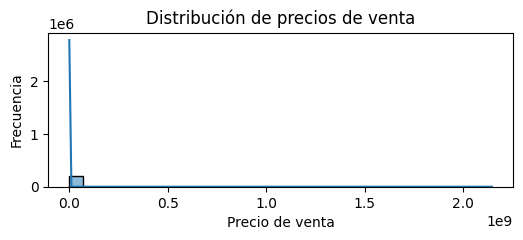

In [ ]:
plt.figure(figsize=(6, 2))
sns.histplot(data = df, x = 'sellPrice', bins = 30, kde = True)
plt.xlabel('Precio de venta')
plt.ylabel('Frecuencia')
plt.title('Distribución de precios de venta')
plt.show()
#

In [ ]:
df.sellPrice.max()

2147483647

## Transformación logarítmica

Apresurando una transformación logarítmica con numpy, podemos ver un cambio en la distribución que ahora tiene una forma mucho más "normalizada". ¡Recuerde! No es magia, se trata de nuevos valores, otra variable, y un cambio en las unidades.
  
¿Y qué ha pasado con los outliers? Ejercicio para el estudiante:
1. Contabilice la cantidad de outliers superiores que hay en la variable original según el criterio IQR.  
2. Repita para la variable transformada, sellPrice_log.

In [ ]:
df.sellPrice

,sellPrice
0,1210000
1,2250000
2,2920000
3,1530000
4,8000000
...,...
199499,1900000
199500,980000
199501,850000
199502,640000


In [ ]:
np.log1p(df.sellPrice)

,sellPrice
0,14.006132
1,14.626441
2,14.887095
3,14.240779
4,15.894952
...,...
199499,14.457365
199500,13.795309
199501,13.652993
199502,13.369225


In [ ]:
df['sellPrice_log'] = np.log1p(df.sellPrice)

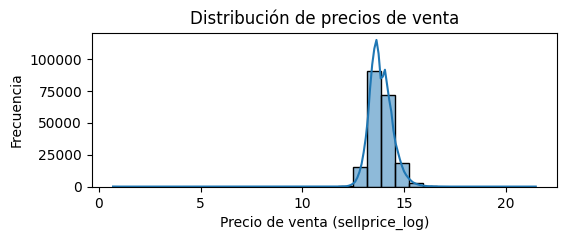

In [ ]:
plt.figure(figsize=(6, 2))
sns.histplot(data = df, x = 'sellPrice_log', bins = 30, kde = True)
plt.xlabel('Precio de venta (sellprice_log)')
plt.ylabel('Frecuencia')
plt.title('Distribución de precios de venta')
plt.show()
#

## Capping
Probemos ahora poner un umbral o threshold, pasado el cuál todos los valores tendrán el mismo valor. Pandas incluye un método muy útil para hacerlo, clip.

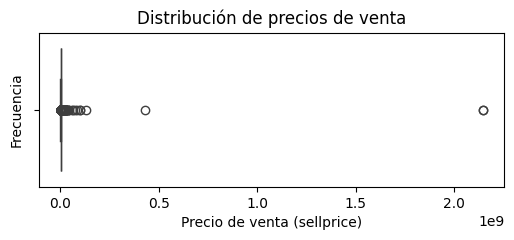

In [ ]:
plt.figure(figsize=(6, 2))
sns.boxplot(data = df, x = 'sellPrice')
plt.xlabel('Precio de venta (sellprice)')
plt.ylabel('Frecuencia')
plt.title('Distribución de precios de venta')
plt.show()
#

In [ ]:
df['sellPrice'].max() == df['sellPrice'].quantile(1)

np.True_

In [ ]:
df['sellPrice'].min() == df['sellPrice'].quantile(0.00)

np.True_

In [ ]:
# Calcularemos primero los percentiles extremos inferior y superios.
p1_price = df['sellPrice'].quantile(0.01)
p99_price = df['sellPrice'].quantile(0.99)

In [ ]:
# La funcion clip nos ofrece dos parametros para elegir los puntos de corte
df['sellPrice_capped'] = df['sellPrice'].clip(lower = p1_price, upper = p99_price)
#

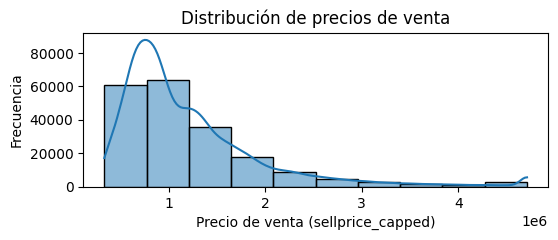

In [ ]:
plt.figure(figsize=(6, 2))
sns.histplot(data = df, x = 'sellPrice_capped', bins = 10, kde = True)
plt.xlabel('Precio de venta (sellprice_capped)')
plt.ylabel('Frecuencia')
plt.title('Distribución de precios de venta')
plt.show()
#

¡Increíble cambio! Esto es muy similar a la forma que se obtiene simplemente recortando la variable y quitando los outliers. ¿Por qué? Pues porque el resto del dataset sigue igual. Note ahora cómo el último bin tiene un crecimiento abrupto sobre el decrecimiento de la distribución; han quedado allí todas las muestras superiores concentradas.

Trabajaremos un poco con la variable Date, para convertir su tipo y extraer año y mes de venta.


Ejercicio: dibuje Boxplots para las tres variables anteriores y compare.

# Imputación de faltantes

Revisemos nuevamente los datos faltantes por columna. Car parece tener serios problemas.

In [ ]:
df.isna().sum()

,0
Date,0
Id,0
suburb,0
postalCode,0
sellPrice,0
bed,154
bath,0
car,18151
propType,0
sellPrice_log,0


In [ ]:
# verificamos si cuenta con 0 explicitos la columna 'car'
df.car.unique()

array([ 2.,  4.,  3.,  1., nan,  7.,  9.,  5.,  6.,  8., 30., 10., 12.,
       11., 16., 18., 13., 20., 15., 24., 14., 41., 22., 17., 29., 21.,
       31.])

In [ ]:
df.car.value_counts()

,count
car,
2.0,91044
1.0,61894
3.0,15575
4.0,8899
5.0,1699
6.0,1294
8.0,302
7.0,274
10.0,147


La primera alternativa estudiada anteriormente es la eliminación de los registros (del dataframe quizás, ¡nunca de la fuente original!)   
Imputemos ahora los valores con la media.

In [ ]:
df.car

,car
0,2.0
1,4.0
2,2.0
3,2.0
4,4.0
...,...
199499,7.0
199500,2.0
199501,2.0
199502,2.0


**Considerar imputar por '0', ya que como vimos los nulls muy probablemente representan propiedades sin estacionamientos.**

Aplicaremos la estrategia de imputación por una medida de posición central, solo a modo ilustrativo

In [ ]:
car_mean = df.car.mean()

In [ ]:
car_mean

np.float64(1.936223828665641)

In [ ]:
 # usamos la función fillna
df['car_inputed'] = df['car'].fillna(car_mean)   # como argumento le damos el promedio de df.car

In [ ]:
df.columns

Index(['Date', 'Id', 'suburb', 'postalCode', 'sellPrice', 'bed', 'bath', 'car',
       'propType', 'sellPrice_log', 'sellPrice_capped', 'car_inputed'],
      dtype='object')

In [ ]:
print(df.car_inputed.isna().sum())
#

0


In [ ]:
print(df.car_inputed.mean())

1.9362238286656412


### Media por grupos
Agruparemos con la funcion "groupby". Esta función, genera distintos subsets del dataframe original. Es equivalente a filtrar el dataframe para quedarnos con distintos conjuntos donde cada subconjunto tiene un únco tipo de valor de esa categoría.

df.groupby('propType')['car'] separa el dataframe por el propType. Luego, toma la columna car como típicamente sucede con el indexado en este formato ("[]").
La función transform calculará la media para cada uno de esos grupos.

Lo importante, que es confuso al principio pero muy útil en el futuro, es que esta operación es **vectorial**; es decir que se repite para todas las estructuras por separado (subgrupos separados por prorType).

El método fillna del dataFrame, aplicará de forma automática el rellenado según el propType de la fila que tenga NaNs en cada caso.


In [ ]:
car_mean

np.float64(1.936223828665641)

In [ ]:
df.groupby('propType')['car']

In [ ]:
df.groupby('propType')['car'].agg('mean')

,car
propType,
acreage,3.700000
duplex/semi-detached,1.553667
house,1.999283
other,2.558333
terrace,1.496626
townhouse,1.646291
villa,1.433756
warehouse,2.925926


In [ ]:
group_means = df.groupby('propType')['car'].mean()
group_means

,car
propType,
acreage,3.700000
duplex/semi-detached,1.553667
house,1.999283
other,2.558333
terrace,1.496626
townhouse,1.646291
villa,1.433756
warehouse,2.925926


Puede verse que la media ha cambiado ligeramente, pues ahora hemos introducido variabilidad (distintos valores, y no una única media). ¿Qué problema creen los estudiantes que podría tener este método? Quizás un subgrupo entero de propTye, o de suburb, o cualquier otra categoría, tenga NaN en car. Entonces, no habría valor con el cual imputar.

Ahora no tenemos nulos, y la media es la misma pues hemos agregado valores sin ningún tipo de dispersión.

# Feature Engineering

Empecemos a revisar la **transformación de variables y creación de nuevas variables**

## Extracción
Como ejemplo simple, tenemos en este dataset fecha de venta. Podemos asegurarnos que el formato sea el correcto (pandas debe interpretar que es una fecha, formato 'datetime' para las operaciones que siguen).

Podemos extraer directamente el año y día de las operaciones. Quizás, podríamos estudiar si los precios de venta tienen distinto comportamiento en distintos meses por ejemplo

In [ ]:
df.Date

,Date
0,2019-06-19
1,2019-06-13
2,2019-06-07
3,2019-05-28
4,2019-05-22
...,...
199499,2014-06-20
199500,2014-05-26
199501,2014-04-17
199502,2013-09-07


In [ ]:
df.Date.info()

<class 'pandas.core.series.Series'>
RangeIndex: 199504 entries, 0 to 199503
Series name: Date
Non-Null Count   Dtype 
--------------   ----- 
199504 non-null  object
dtypes: object(1)
memory usage: 1.5+ MB


In [ ]:
df.Date = pd.to_datetime(df.Date, errors='coerce')

 # errors='coerce' pondrá NaT si no puede parsear

In [ ]:
 # Lunes=0, Domingo=6
df['yearSold'] = df['Date'].dt.year
df['monthSold'] = df['Date'].dt.month
df['daySold'] = df['Date'].dt.day
df['weekdaySold'] = df['Date'].dt.dayofweek  # Lunes=0, Domingo=6
df['dayofYear'] = df['Date'].dt.dayofyear

In [ ]:
print(df[['Date', 'yearSold', 'monthSold', 'daySold', 'dayofYear', 'weekdaySold']])

             Date  yearSold  monthSold  daySold  dayofYear  weekdaySold
0      2019-06-19      2019          6       19        170            2
1      2019-06-13      2019          6       13        164            3
2      2019-06-07      2019          6        7        158            4
3      2019-05-28      2019          5       28        148            1
4      2019-05-22      2019          5       22        142            2
...           ...       ...        ...      ...        ...          ...
199499 2014-06-20      2014          6       20        171            4
199500 2014-05-26      2014          5       26        146            0
199501 2014-04-17      2014          4       17        107            3
199502 2013-09-07      2013          9        7        250            5
199503 2011-04-16      2011          4       16        106            5

[199504 rows x 6 columns]


In [ ]:
df.head()

,Date,Id,suburb,postalCode,sellPrice,bed,bath,car,propType,sellPrice_log,sellPrice_capped,car_inputed,yearSold,monthSold,daySold,weekdaySold,dayofYear
0,2019-06-19,1,Avalon Beach,2107,1210000,4.0,2,2.0,house,14.006132,1210000,2.0,2019,6,19,2,170
1,2019-06-13,2,Avalon Beach,2107,2250000,4.0,3,4.0,house,14.626441,2250000,4.0,2019,6,13,3,164
2,2019-06-07,3,Whale Beach,2107,2920000,3.0,3,2.0,house,14.887095,2920000,2.0,2019,6,7,4,158
3,2019-05-28,4,Avalon Beach,2107,1530000,3.0,1,2.0,house,14.240779,1530000,2.0,2019,5,28,1,148
4,2019-05-22,5,Whale Beach,2107,8000000,5.0,4,4.0,house,15.894952,4710000,4.0,2019,5,22,2,142


# Ejemplo adicional: features de calendario

In [ ]:
# Estacion del año a partir del mes (hemisferio sur)
def season_from_month(m):
  # vereano Dic-Febrero | Otoño: Mar-May | Invierno: Jun-Ago | Primavera: Sep-Nov
  if m in (12, 1, 2):
    return 'verano'
  if m in (3, 4, 5):
    return 'otono'
  if m in (6, 7, 8):
    return 'invierno'
  return 'primavera'

df['seasonSold'] =  df['monthSold'].apply(season_from_month)
df['isWeekend'] = (df['weekdaySold']>=5).astype(int)
df['quarterSold'] = df['Date'].dt.quarter

print(df[['Date','monthSold', 'seasonSold', 'weekdaySold', 'isWeekend', 'quarterSold']])

             Date  monthSold seasonSold  weekdaySold  isWeekend  quarterSold
0      2019-06-19          6   invierno            2          0            2
1      2019-06-13          6   invierno            3          0            2
2      2019-06-07          6   invierno            4          0            2
3      2019-05-28          5      otono            1          0            2
4      2019-05-22          5      otono            2          0            2
...           ...        ...        ...          ...        ...          ...
199499 2014-06-20          6   invierno            4          0            2
199500 2014-05-26          5      otono            0          0            2
199501 2014-04-17          4      otono            3          0            2
199502 2013-09-07          9  primavera            5          1            3
199503 2011-04-16          4      otono            5          1            2

[199504 rows x 6 columns]


## Combinación de variables - Interacción

Aplicamos un remplazo de los valores '0' y 'nan' dentro de la columna `bed`, a modo de simplificar la operación de ratio:

In [ ]:
df.bed.unique()

array([ 4.,  3.,  5.,  6.,  2.,  7.,  8.,  1., nan, 10.,  9., 12., 15.,
       19., 26., 20., 14., 24., 13., 30., 16., 36., 18., 23., 11., 17.,
       99., 22., 45., 21., 34.])

### Ratios

In [ ]:
df.bed = df.bed.replace(0, 1).fillna(1) # Reemplaza 0 y NaN con 1 para evitar error

In [ ]:
df['pricePerBed'] = df.sellPrice / df.bed
#df['pricePerCar'] = df.sellPrice / df.car

In [ ]:
print('Nueva feature creada:')
print(df[['sellPrice', 'bed', 'pricePerBed']])

Nueva feature creada:
        sellPrice  bed   pricePerBed
0         1210000  4.0  3.025000e+05
1         2250000  4.0  5.625000e+05
2         2920000  3.0  9.733333e+05
3         1530000  3.0  5.100000e+05
4         8000000  5.0  1.600000e+06
...           ...  ...           ...
199499    1900000  5.0  3.800000e+05
199500     980000  4.0  2.450000e+05
199501     850000  4.0  2.125000e+05
199502     640000  3.0  2.133333e+05
199503    1611000  5.0  3.222000e+05

[199504 rows x 3 columns]


### Sumas/Diferencias

In [ ]:
df['bed_plus_car'] = df.bed + df.car.fillna(0) # Rellenar Nans en Car con 0 para la suma
#df['bed_minus_car'] = df.bed - df.car
print('Nueva feature creada:')
print(df[['bed', 'car', 'bed_plus_car']])

Nueva feature creada:
        bed  car  bed_plus_car
0       4.0  2.0           6.0
1       4.0  4.0           8.0
2       3.0  2.0           5.0
3       3.0  2.0           5.0
4       5.0  4.0           9.0
...     ...  ...           ...
199499  5.0  7.0          12.0
199500  4.0  2.0           6.0
199501  4.0  2.0           6.0
199502  3.0  2.0           5.0
199503  5.0  3.0           8.0

[199504 rows x 3 columns]


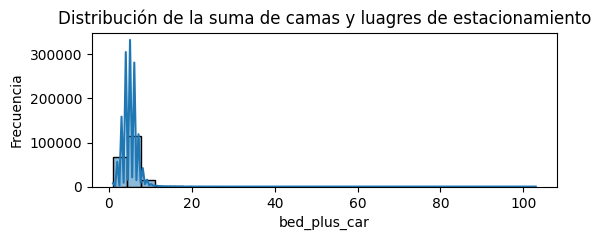

In [ ]:
plt.figure(figsize=(6, 2))
sns.histplot(data = df, x = 'bed_plus_car', bins = 30, kde = True)
plt.xlabel('bed_plus_car')
plt.ylabel('Frecuencia')
plt.title('Distribución de la suma de camas y luagres de estacionamiento')
plt.show()
#

¿Qué otras variables cree que podrían ser de valor?
Proponga al menos tres.

## Binning

Agruparemos los precios de las propiedades. Primero, por montos predefinidos y luego por cuantiles.

In [ ]:
help(pd.cut)

Help on function cut in module pandas.core.reshape.tile:

cut(
    x,
    bins,
    right: 'bool' = True,
    labels=None,
    retbins: 'bool' = False,
    precision: 'int' = 3,
    include_lowest: 'bool' = False,
    duplicates: 'str' = 'raise',
    ordered: 'bool' = True
)
    Bin values into discrete intervals.

    Use `cut` when you need to segment and sort data values into bins. This
    function is also useful for going from a continuous variable to a
    categorical variable. For example, `cut` could convert ages to groups of
    age ranges. Supports binning into an equal number of bins, or a
    pre-specified array of bins.

    Parameters
    ----------
    x : array-like
        The input array to be binned. Must be 1-dimensional.
    bins : int, sequence of scalars, or IntervalIndex
        The criteria to bin by.

        * int : Defines the number of equal-width bins in the range of `x`. The
          range of `x` is extended by .1% on each side to include the minimum
   

In [ ]:
# Binning de sellPrice con pd.cut()
price_bins = [0, 500000, 1000000, 1500000, 2000000, 3000000, np.inf]
price_labels = ['0-500k', '500k-1m', '1m-1.5m', '1.5m-2m', '2m-3m', '3m+']

In [ ]:
pd.set_option('display.float_format','{:,.2f}'.format)
df.sellPrice.describe()
#pd.reset_option('display.float_format')

,sellPrice
count,"199,504.00"
mean,"1,269,776.30"
std,"6,948,239.27"
min,1.00
25%,"720,000.00"
50%,"985,000.00"
75%,"1,475,000.00"
max,"2,147,483,647.00"


In [ ]:
df.sellPrice

,sellPrice
0,1210000
1,2250000
2,2920000
3,1530000
4,8000000
...,...
199499,1900000
199500,980000
199501,850000
199502,640000


In [ ]:
pd.cut(df.sellPrice, bins=price_bins, labels=price_labels)

,sellPrice
0,1m-1.5m
1,2m-3m
2,2m-3m
3,1.5m-2m
4,3m+
...,...
199499,1.5m-2m
199500,500k-1m
199501,500k-1m
199502,500k-1m


In [ ]:
df['sellPrice_category_cut'] = pd.cut(df.sellPrice, bins=price_bins, labels=price_labels, right=False)
print(df['sellPrice_category_cut'].value_counts().sort_index() * 100)
#

sellPrice_category_cut
0-500k     1296900
500k-1m    8814200
1m-1.5m    4966500
1.5m-2m    2490400
2m-3m      1587800
3m+         794600
Name: count, dtype: int64


In [ ]:
# Binning de sellPrice con pd.qcut() (cuantiles)
df['sellPrice_category_qcut'] = pd.qcut(df.sellPrice, q=4, labels=['Q1_Price', 'Q2_Price', 'Q3_Price', 'Q4_Price'], duplicates= 'drop')
print("Nueva feature creada: 'sellPrice_category_qcut'")
print(df['sellPrice_category_qcut'].value_counts().sort_index() * 100)


Nueva feature creada: 'sellPrice_category_qcut'
sellPrice_category_qcut
Q1_Price    5021500
Q2_Price    4958300
Q3_Price    5001700
Q4_Price    4968900
Name: count, dtype: int64


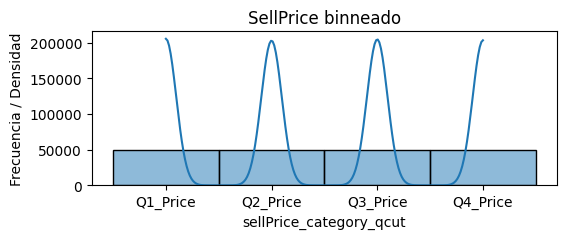

In [ ]:
plt.figure(figsize=(6, 2))
sns.histplot(data = df, x = 'sellPrice_category_qcut', bins = 30, kde = True)
plt.xlabel('sellPrice_category_qcut')
plt.ylabel('Frecuencia / Densidad')
plt.title('SellPrice binneado')
plt.show()
#

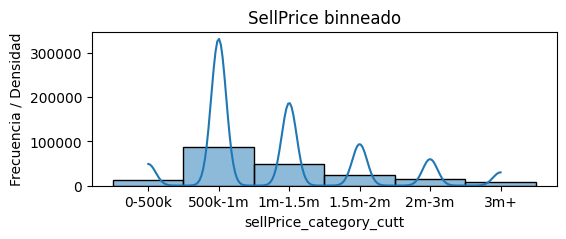

In [ ]:
plt.figure(figsize=(6, 2))
sns.histplot(data = df, x = 'sellPrice_category_cut', bins = 30, kde = True)
plt.xlabel('sellPrice_category_cutt')
plt.ylabel('Frecuencia / Densidad')
plt.title('SellPrice binneado')
plt.show()
#

¿Qué observa en las distribuciones? ¿Por qué la segunda tiene esa forma tan pareja? Recuerde la definición de cuartiles.

# Transformaciones

Ya hicimos antes, la transformación logarítmica de sellPrice. Miremos otro aspecto de esa transformación: la relación contra otra variable.

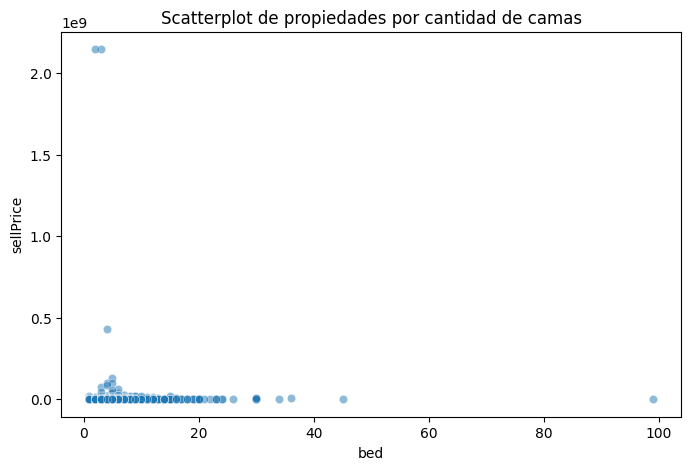

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='bed', y='sellPrice', alpha=0.5)
plt.title('Scatterplot de propiedades por cantidad de camas')
plt.show()
#

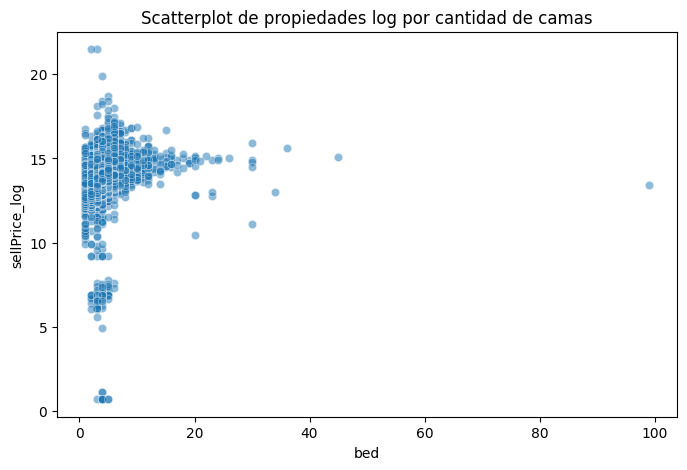

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='bed', y='sellPrice_log', alpha=0.5)
plt.title('Scatterplot de propiedades log por cantidad de camas')
plt.show()
#

Ejercicio: realice dos delas siguientes tres transformaciones y grafique la distribución:
- y = 1/x
- y = sqrt(x)
- y = x**2

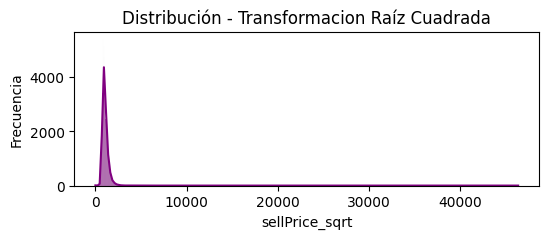

In [ ]:
# 1. Primera transformación elegida: Raiz cuadrada (y = sqrt(x))

df['sellPrice_sqrt'] =  np.sqrt(df['sellPrice'])

plt.figure(figsize=(6, 2))
sns.histplot(df['sellPrice_sqrt'], kde=True, color='purple')
plt.title('Distribución - Transformacion Raíz Cuadrada')
plt.xlabel('sellPrice_sqrt')
plt.ylabel('Frecuencia')
plt.show()


In [ ]:
# Segunda transformación elegida: Funcion inversa (y=1/x)

df['sellPrice_inv'] = 1 / df['sellPrice']

plt.figure(figsize=(8, 6))
sns.histplot(df['sellPrice_inv'], kde=True, color='green')
plt.title('Distribución - Transformacion Inversa (1/x)')
plt.xlabel('sellPrice_inv')
plt.ylabel('Frecuencia')
plt.show()

## Escalado

Utilizaremos una función que permite escalar de forma directa, sin tener que hacer los cálculos definidos en la diapositiva teórica..

1. Creamos un objeto Scaler. Por ejemplo, MinMaxScaler o StandardScaler.
2. Este tipo de objetos tienen dos pasos para su aplicación. Primero, "fit" que prepara los argumentos y ejecuta algún mecanismo interno. Luego, "transform", que modifica realmente los datos según los parámetros establecidos. En este caso, por la simpleza de la operación, podemos usar una opción abreviada: fit_transform.

Pertenece a un paquete llamado sklearn que utilizaremos con mucha frecuencia.

In [ ]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

Es muy importante que note cómo hemos escrito el argumento de fit_transform:  
df[['sellPrice']]

¿A qué se debe este doble corchete? Intente quitar un par de corchetes y lea el error. Está relacionado con la **dimensión** del objeto que recibe el scaler. Necesita un arreglo bidimensional, y al enviar una sola columna estamos pasando un arreglo de una sola dimensión. Es un tecnicismo de importancia, son errores que pueden ser frustrantes.


Mostraremos .head() para los datos originales, y los escalados con ambos métodos. Observe las diferencias numéricas.

In [ ]:
# MinMaxScaler
scaler_minmax = MinMaxScaler()
scaler_minmax.fit(df[['sellPrice']]) # .fir -> .transform()
df['sellPrice_minmax'] = scaler_minmax.transform(df[['sellPrice']])

In [ ]:
df['sellPrice_minmax'].describe()

,sellPrice_minmax
count,"199,504.00"
mean,0.00
std,0.00
min,0.00
25%,0.00
50%,0.00
75%,0.00
max,1.00


In [ ]:
# StandardScaler
scaler_standard = StandardScaler()
df['sellPrice_std'] = scaler_standard.fit_transform(df[['sellPrice']])

In [ ]:
df['sellPrice_std'].describe()

,sellPrice_std
count,"199,504.00"
mean,0.00
std,1.00
min,-0.18
25%,-0.08
50%,-0.04
75%,0.03
max,308.89


In [ ]:
print("Ejemplo de Escalado para sellPrice (muestra de 5):")
print("Original:")
print(df.sellPrice.head())
print("Con MinMaxScaler (0-1):")
print(df.sellPrice_minmax.head())
print("Con StandardScaler (Media o, Std 1):")
print(df.sellPrice_std.head())

Ejemplo de Escalado para sellPrice (muestra de 5):
Original:
0    1210000
1    2250000
2    2920000
3    1530000
4    8000000
Name: sellPrice, dtype: int64
Con MinMaxScaler (0-1):
0   0.00
1   0.00
2   0.00
3   0.00
4   0.00
Name: sellPrice_minmax, dtype: float64
Con StandardScaler (Media o, Std 1):
0   -0.01
1    0.14
2    0.24
3    0.04
4    0.97
Name: sellPrice_std, dtype: float64


Ejercicio: compare la media y desvío de cada una de estas tres variables.


# Encodings

## One-Hot Encoding
Podemos utilizar de forma directa el método de pandas get_dummies. El argumento prefix, nos permite escribir un string que será el prefijo de todas las nuevas columnas.

In [ ]:
df.columns

Index(['Date', 'Id', 'suburb', 'postalCode', 'sellPrice', 'bed', 'bath', 'car',
       'propType', 'sellPrice_log', 'sellPrice_capped', 'car_inputed',
       'yearSold', 'monthSold', 'daySold', 'weekdaySold', 'dayofYear',
       'seasonSold', 'isWeekend', 'quarterSold', 'pricePerBed', 'bed_plus_car',
       'sellPrice_category_cut', 'sellPrice_category_qcut', 'sellPrice_minmax',
       'sellPrice_std'],
      dtype='object')

In [ ]:
pd.get_dummies(df.propType, prefix='propType', dummy_na=False).replace({False:0})

,propType_acreage,propType_duplex/semi-detached,propType_house,propType_other,propType_terrace,propType_townhouse,propType_villa,propType_warehouse
0,0,0,True,0,0,0,0,0
1,0,0,True,0,0,0,0,0
2,0,0,True,0,0,0,0,0
3,0,0,True,0,0,0,0,0
4,0,0,True,0,0,0,0,0
...,...,...,...,...,...,...,...,...
199499,0,0,True,0,0,0,0,0
199500,0,0,True,0,0,0,0,0
199501,0,0,True,0,0,0,0,0
199502,0,0,0,0,0,True,0,0


Note todas las columnas que se generan: una por cada cateogría. Así como usamos los Scalers anteriormente, sklearn también nos provee de Encoders.

In [ ]:
from sklearn.preprocessing import OneHotEncoder, LabelEncoder

Esta vez, lo haremos por pasos para observar la operatoria de fit / transform por separado. Será MUY similar el trabajo con los modelos de Machine Learning.

In [ ]:
help(OneHotEncoder)

Help on class OneHotEncoder in module sklearn.preprocessing._encoders:

class OneHotEncoder(_BaseEncoder)
 |  OneHotEncoder(
 |      *,
 |      categories='auto',
 |      drop=None,
 |      sparse_output=True,
 |      dtype=<class 'numpy.float64'>,
 |      handle_unknown='error',
 |      min_frequency=None,
 |      max_categories=None,
 |      feature_name_combiner='concat'
 |  )
 |
 |  Encode categorical features as a one-hot numeric array.
 |
 |  The input to this transformer should be an array-like of integers or
 |  strings, denoting the values taken on by categorical (discrete) features.
 |  The features are encoded using a one-hot (aka 'one-of-K' or 'dummy')
 |  encoding scheme. This creates a binary column for each category and
 |  returns a sparse matrix or dense array (depending on the ``sparse_output``
 |  parameter).
 |
 |  By default, the encoder derives the categories based on the unique values
 |  in each feature. Alternatively, you can also specify the `categories`
 |  m

Instancia:

In [ ]:
encoder = OneHotEncoder(handle_unknown= 'ignore' , sparse_output= False)
encoder

OneHotEncoder(handle_unknown='ignore', sparse_output=False)

Entrenamiento:

In [ ]:
# Ajusta el encoder aprendiendo las categorias de la columna
encoder.fit(df[['propType']])

OneHotEncoder(handle_unknown='ignore', sparse_output=False)

In [ ]:
# Muestra los nombres de las columnas codificadas luego del aprendizaje
encoder.get_feature_names_out()


array(['propType_acreage', 'propType_duplex/semi-detached',
       'propType_house', 'propType_other', 'propType_terrace',
       'propType_townhouse', 'propType_villa', 'propType_warehouse'],
      dtype=object)

In [ ]:
# Visualiza las columnas actuales del DataFrame
df.columns

Index(['Date', 'Id', 'suburb', 'postalCode', 'sellPrice', 'bed', 'bath', 'car',
       'propType', 'sellPrice_log', 'sellPrice_capped', 'car_inputed',
       'yearSold', 'monthSold', 'daySold', 'weekdaySold', 'dayofYear',
       'seasonSold', 'isWeekend', 'quarterSold', 'pricePerBed', 'bed_plus_car',
       'sellPrice_category_cut', 'sellPrice_category_qcut', 'sellPrice_minmax',
       'sellPrice_std'],
      dtype='object')

Transformación:

In [ ]:
# Transforma la variabe categorica a formtado One-Hot
encoded = encoder.transform(df[['propType']])
# Mostrar los datos codificados
encoded

array([[0., 0., 1., ..., 0., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       ...,
       [0., 0., 1., ..., 0., 0., 0.],
       [0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.]])

La salida es un array, naturalmente sin etiquetas de columnas. Los nombres de las etiquetas estarán en el objeto Encoder.

In [ ]:
# Obtener los nombres de las columnas generadas por el encoder
encoded_columns = encoder.get_feature_names_out()

In [ ]:
df.index # revisar el indice original del df

RangeIndex(start=0, stop=199504, step=1)

In [ ]:
# Creamos un dataframe con las variables codificadas
df_propType_encoded = pd.DataFrame(
    data = encoded,
    columns = encoded_columns,
    index = df.index # nos copiamos el indice original del df
    )

In [ ]:
df_propType_encoded

,propType_acreage,propType_duplex/semi-detached,propType_house,propType_other,propType_terrace,propType_townhouse,propType_villa,propType_warehouse
0,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
1,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
2,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
3,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
4,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
...,...,...,...,...,...,...,...,...
199499,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
199500,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
199501,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
199502,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00


In [ ]:
help(pd.concat)

Help on function concat in module pandas.core.reshape.concat:

concat(
    objs: 'Iterable[Series | DataFrame] | Mapping[HashableT, Series | DataFrame]',
    *,
    axis: 'Axis' = 0,
    join: 'str' = 'outer',
    ignore_index: 'bool' = False,
    keys: 'Iterable[Hashable] | None' = None,
    levels=None,
    names: 'list[HashableT] | None' = None,
    verify_integrity: 'bool' = False,
    sort: 'bool' = False,
    copy: 'bool | None' = None
) -> 'DataFrame | Series'
    Concatenate pandas objects along a particular axis.

    Allows optional set logic along the other axes.

    Can also add a layer of hierarchical indexing on the concatenation axis,
    which may be useful if the labels are the same (or overlapping) on
    the passed axis number.

    Parameters
    ----------
    objs : a sequence or mapping of Series or DataFrame objects
        If a mapping is passed, the sorted keys will be used as the `keys`
        argument, unless it is passed, in which case the values will be


In [ ]:
# Concatena ambos DataFrames agregando columnas (axis=1).
# Revisamos el resultado antes de guardarlo..

pd.concat([df, df_propType_encoded], axis= 1)

,Date,Id,suburb,postalCode,sellPrice,bed,bath,car,propType,sellPrice_log,...,sellPrice_minmax,sellPrice_std,propType_acreage,propType_duplex/semi-detached,propType_house,propType_other,propType_terrace,propType_townhouse,propType_villa,propType_warehouse
0,2019-06-19,1,Avalon Beach,2107,1210000,4.00,2,2.00,house,14.01,...,0.00,-0.01,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
1,2019-06-13,2,Avalon Beach,2107,2250000,4.00,3,4.00,house,14.63,...,0.00,0.14,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
2,2019-06-07,3,Whale Beach,2107,2920000,3.00,3,2.00,house,14.89,...,0.00,0.24,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
3,2019-05-28,4,Avalon Beach,2107,1530000,3.00,1,2.00,house,14.24,...,0.00,0.04,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
4,2019-05-22,5,Whale Beach,2107,8000000,5.00,4,4.00,house,15.89,...,0.00,0.97,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199499,2014-06-20,199500,Illawong,2234,1900000,5.00,3,7.00,house,14.46,...,0.00,0.09,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
199500,2014-05-26,199501,Illawong,2234,980000,4.00,3,2.00,house,13.80,...,0.00,-0.04,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
199501,2014-04-17,199502,Alfords Point,2234,850000,4.00,2,2.00,house,13.65,...,0.00,-0.06,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
199502,2013-09-07,199503,Illawong,2234,640000,3.00,2,2.00,townhouse,13.37,...,0.00,-0.09,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00


In [ ]:
# df_preprocessed = pd.concat([df, df_propType_encoded], axis=1)


Resta incorporarlo al dataframe o guardarlo en uno nuevo. Se deja como ejercicio.

## Label Encoding

Instacia:

In [ ]:
# Crea un codificador para convertir categorías en valores numéricos.
label_encoder = LabelEncoder()

Entrenamiento y transformación:

In [ ]:
# Creamos una nueva columna para conservar la original
# Codifica la columna categórica y guarda el resultado en una nueva columna.

df['propType_LabelEncoded'] = label_encoder.fit_transform(df['propType'])

In [ ]:
df.propType_LabelEncoded

,propType_LabelEncoded
0,2
1,2
2,2
3,2
4,2
...,...
199499,2
199500,2
199501,2
199502,5


Vemos que el Encoder ha codificado la variable pero no sabemos a qué categoría corresponde cada número.

### Recapitulando

| Técnica | Qué hace | Cuándo usarla |
|--------|----------|---------------|
| Extracción temporal | Año, mes, estación, flags | Fechas / estacionalidad |
| Interacciones / ratios | Combina variables | Relaciones de negocio |
| Binning | Continuo → categorías | No linealidad / reportes |
| Transformaciones | log, sqrt, 1/x, x² | Asimetrías / outliers |
| Escalado | Misma escala numérica | Modelos sensibles a escala |
| One-Hot / Label / Freq | Categorías → números | Encoding según cardinalidad |

**Regla de oro:** toda transformación que use estadísticas del dataset (media, cuantiles, target encoding) debe calcularse **solo con train** y luego aplicarse a validación/test.
